# 📊 Exploratory Data Analysis — Data Inovasi & Kewirausahaan FIF

**Tanggal:** 2026-11-11  
**Sumber Data:** Output pipeline ETL (`output/`)  
**Notebook:** `code/eda_fif_inovasi.ipynb`

---

Notebook ini melakukan analisis eksplorasi terhadap 3 dataset yang sudah dibersihkan:
1. **Data KI FIF** — Kekayaan Intelektual (Hak Cipta, Paten, Merek, Desain Industri)
2. **Data Startup FIF** — 53 startup dari tahun 2025-2026
3. **Peserta Inkubasi FIF** — 44 peserta dari 16 tim startup


## 0️⃣ Setup & Import


In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import numpy as np
from collections import Counter
import re
import warnings
warnings.filterwarnings('ignore')

# Style
plt.style.use('seaborn-v0_8-whitegrid')
plt.rcParams.update({
    'figure.figsize': (12, 6),
    'font.size': 11,
    'axes.titlesize': 14,
    'axes.titleweight': 'bold',
    'figure.dpi': 100,
})

COLORS = ['#2196F3', '#4CAF50', '#FF9800', '#E91E63', '#9C27B0', '#00BCD4', '#FF5722', '#607D8B']
print('✅ Setup selesai')


✅ Setup selesai


## 1️⃣ Load Data


In [2]:
df_ki = pd.read_csv('../output/clean_data_ki_fif.csv')
df_st = pd.read_csv('../output/clean_data_startup_fif.csv')
df_ink = pd.read_csv('../output/clean_peserta_inkubasi_fif.csv')

print(f'📦 Data KI FIF       : {df_ki.shape[0]} baris × {df_ki.shape[1]} kolom')
print(f'📦 Data Startup FIF  : {df_st.shape[0]} baris × {df_st.shape[1]} kolom')
print(f'📦 Peserta Inkubasi  : {df_ink.shape[0]} baris × {df_ink.shape[1]} kolom')


📦 Data KI FIF       : 147 baris × 10 kolom
📦 Data Startup FIF  : 53 baris × 5 kolom
📦 Peserta Inkubasi  : 44 baris × 8 kolom


In [3]:
# Preview data
display(df_ki.head(3))
display(df_st.head(3))
display(df_ink.head(3))


,no,nama,judul,kategori,status,sudah_di_aplikasikan,objek_pengaplikasian,sudah_di_komersialisasikan,objek_komersialisasi,flag_aplikasi_tanpa_objek
0,1,WARIH MAHARANI,Metode Prediksi Tipe Kepribadian Big Five Berd...,PATEN,Sertifikat Selesai,NaN,NaN,NaN,NaN,False
1,2,WARIH MAHARANI,Metode Perhitungan Rating Produk Berskala 5 Di...,PATEN,Sertifikat Selesai,NaN,NaN,NaN,NaN,False
2,3,MAMAN ABDUROHMAN,Alat untuk Melakukan Presensi Berbasis Pengena...,PATEN,Sertifikat Selesai,NaN,NaN,NaN,NaN,False


,no,nama_startup,batch,tahun,deskripsi
0,1,Safea Indonesia,NaN,2025,Safea Indonesia menjual produk Cold Pressed Ju...
1,2,Jatim Bissa,NaN,2025,Solusi ketenagakerjaan bagi penyandang disabil...
2,3,Handai Coffee,NaN,2025,HandaiCoffee adalah solusi berupa minuman rend...


,no,nama_startup,nama,nim,prodi,fakultas,universitas,flag_nim_duplikat
0,1,Jatim Bissa,Mahasiswa 5741,9.000006e+09,S1 Informatika,FIF,TelU Surabaya,False
1,2,Jatim Bissa,Mahasiswa 1712,9.000002e+09,S1 Informatika,FIF,TelU Surabaya,False
2,3,Jatim Bissa,Mahasiswa 5742,9.000006e+09,S1 Informatika,FIF,TelU Surabaya,False


## 2️⃣ Data Quality Overview

### 2.1 Null Values per Dataset


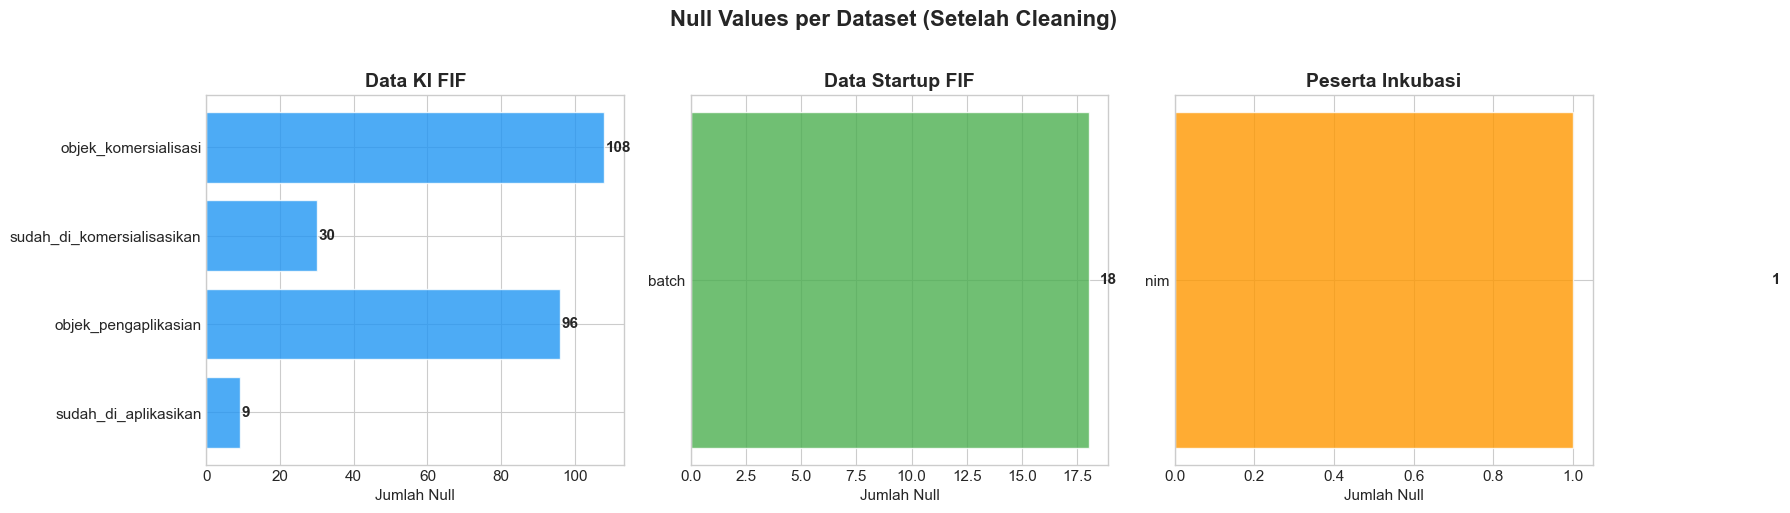

In [4]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

datasets = [
    (df_ki, 'Data KI FIF', COLORS[0]),
    (df_st, 'Data Startup FIF', COLORS[1]),
    (df_ink, 'Peserta Inkubasi', COLORS[2]),
]

for ax, (df, title, color) in zip(axes, datasets):
    nulls = df.isnull().sum()
    nulls = nulls[nulls > 0]
    if len(nulls) == 0:
        ax.text(0.5, 0.5, 'Tidak ada null values! ✅', ha='center', va='center', fontsize=14, transform=ax.transAxes)
    else:
        bars = ax.barh(nulls.index, nulls.values, color=color, alpha=0.8, edgecolor='white')
        for bar, val in zip(bars, nulls.values):
            ax.text(bar.get_width() + 0.5, bar.get_y() + bar.get_height()/2, str(val), va='center', fontweight='bold')
    ax.set_title(title)
    ax.set_xlabel('Jumlah Null')

plt.suptitle('Null Values per Dataset (Setelah Cleaning)', fontsize=16, fontweight='bold', y=1.02)
plt.tight_layout()
plt.savefig('../output/eda_01_null_values.png', bbox_inches='tight', dpi=150)
plt.show()


---

## 3️⃣ Analisis Data Kekayaan Intelektual (KI)

### 3.1 Distribusi Kategori KI


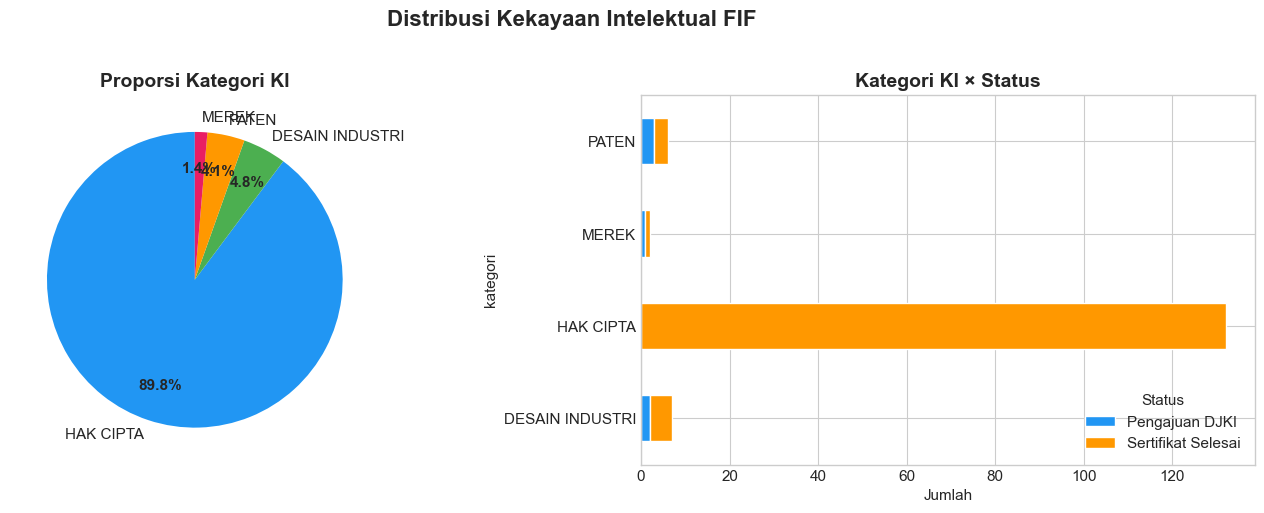

📌 Total KI: 147
📌 Sertifikat Selesai: 141 (95.9%)
📌 Pengajuan DJKI: 6


In [5]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Pie chart kategori
kat_counts = df_ki['kategori'].value_counts()
wedges, texts, autotexts = axes[0].pie(
    kat_counts.values, labels=kat_counts.index, autopct='%1.1f%%',
    colors=COLORS[:len(kat_counts)], startangle=90,
    textprops={'fontsize': 11}, pctdistance=0.75
)
for t in autotexts:
    t.set_fontweight('bold')
axes[0].set_title('Proporsi Kategori KI')

# Bar chart kategori x status
ct = pd.crosstab(df_ki['kategori'], df_ki['status'])
ct.plot(kind='barh', stacked=True, ax=axes[1], color=[COLORS[0], COLORS[2]], edgecolor='white')
axes[1].set_title('Kategori KI × Status')
axes[1].set_xlabel('Jumlah')
axes[1].legend(title='Status', loc='lower right')

plt.suptitle('Distribusi Kekayaan Intelektual FIF', fontsize=16, fontweight='bold', y=1.02)
plt.tight_layout()
plt.savefig('../output/eda_02_ki_kategori.png', bbox_inches='tight', dpi=150)
plt.show()

print(f'📌 Total KI: {len(df_ki)}')
print(f'📌 Sertifikat Selesai: {(df_ki["status"]=="Sertifikat Selesai").sum()} ({(df_ki["status"]=="Sertifikat Selesai").mean()*100:.1f}%)')
print(f'📌 Pengajuan DJKI: {(df_ki["status"]=="Pengajuan DJKI").sum()}')


### 3.2 Aplikasi & Komersialisasi KI


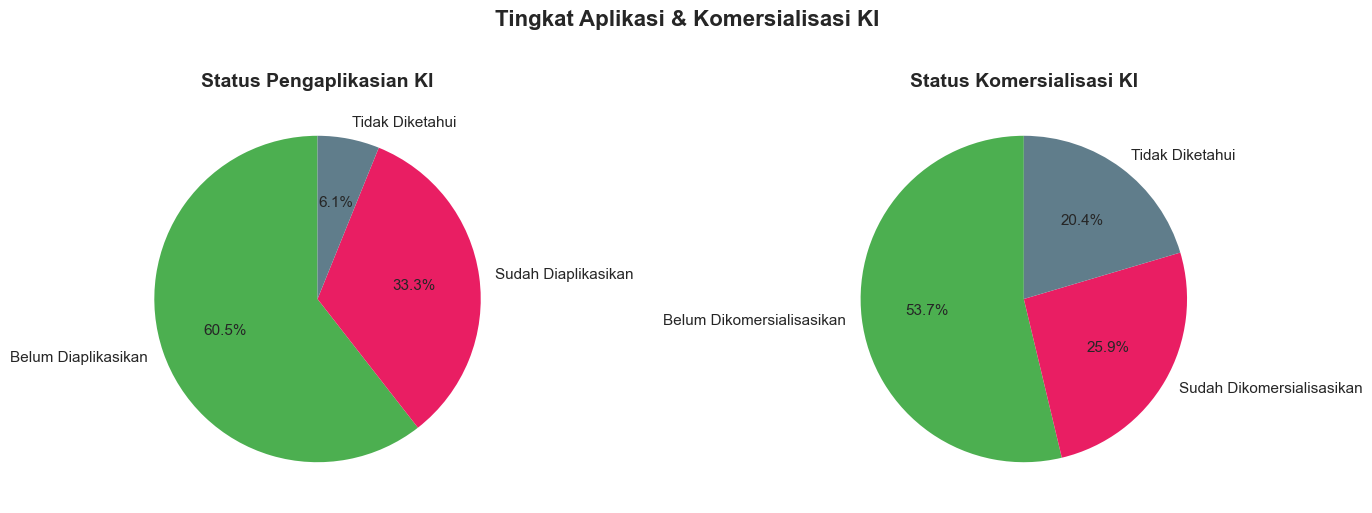

📌 Tingkat Aplikasi: 35.5% dari yang terdata
📌 Tingkat Komersialisasi: 32.5% dari yang terdata


In [6]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Aplikasi
apl_data = df_ki['sudah_di_aplikasikan'].value_counts(dropna=False)
apl_labels = {True: 'Sudah Diaplikasikan', False: 'Belum Diaplikasikan', np.nan: 'Tidak Diketahui'}
labels = [apl_labels.get(k, str(k)) for k in apl_data.index]
axes[0].pie(apl_data.values, labels=labels, autopct='%1.1f%%',
            colors=[COLORS[1], COLORS[3], COLORS[7]], startangle=90,
            textprops={'fontsize': 11})
axes[0].set_title('Status Pengaplikasian KI')

# Komersialisasi
kom_data = df_ki['sudah_di_komersialisasikan'].value_counts(dropna=False)
labels_k = [apl_labels.get(k, str(k)).replace('Diaplikasikan', 'Dikomersialisasikan') for k in kom_data.index]
axes[1].pie(kom_data.values, labels=labels_k, autopct='%1.1f%%',
            colors=[COLORS[1], COLORS[3], COLORS[7]], startangle=90,
            textprops={'fontsize': 11})
axes[1].set_title('Status Komersialisasi KI')

plt.suptitle('Tingkat Aplikasi & Komersialisasi KI', fontsize=16, fontweight='bold', y=1.02)
plt.tight_layout()
plt.savefig('../output/eda_03_ki_aplikasi_komersialisasi.png', bbox_inches='tight', dpi=150)
plt.show()

apl_rate = df_ki['sudah_di_aplikasikan'].dropna().mean() * 100
kom_rate = df_ki['sudah_di_komersialisasikan'].dropna().mean() * 100
print(f'📌 Tingkat Aplikasi: {apl_rate:.1f}% dari yang terdata')
print(f'📌 Tingkat Komersialisasi: {kom_rate:.1f}% dari yang terdata')


### 3.3 Aplikasi & Komersialisasi per Kategori KI


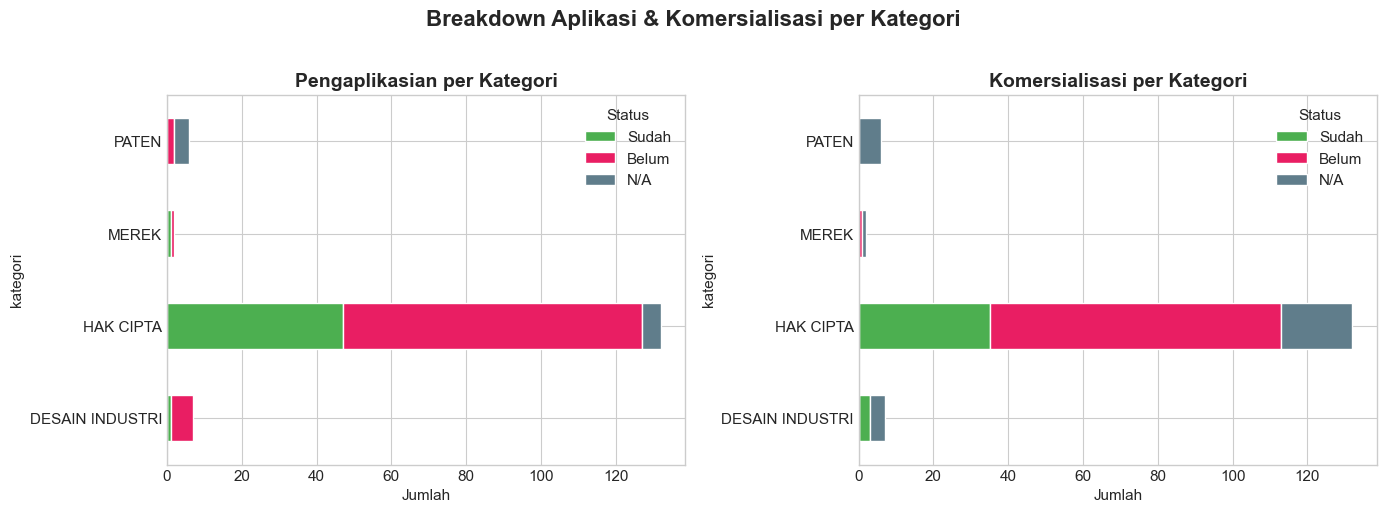

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Aplikasi per kategori
ct_apl = pd.crosstab(df_ki['kategori'], df_ki['sudah_di_aplikasikan'].fillna('N/A'))
ct_apl.columns = ['Belum', 'Sudah', 'N/A']
ct_apl[['Sudah', 'Belum', 'N/A']].plot(kind='barh', stacked=True, ax=axes[0],
    color=[COLORS[1], COLORS[3], COLORS[7]], edgecolor='white')
axes[0].set_title('Pengaplikasian per Kategori')
axes[0].set_xlabel('Jumlah')
axes[0].legend(title='Status')

# Komersialisasi per kategori
ct_kom = pd.crosstab(df_ki['kategori'], df_ki['sudah_di_komersialisasikan'].fillna('N/A'))
ct_kom.columns = ['Belum', 'Sudah', 'N/A']
ct_kom[['Sudah', 'Belum', 'N/A']].plot(kind='barh', stacked=True, ax=axes[1],
    color=[COLORS[1], COLORS[3], COLORS[7]], edgecolor='white')
axes[1].set_title('Komersialisasi per Kategori')
axes[1].set_xlabel('Jumlah')
axes[1].legend(title='Status')

plt.suptitle('Breakdown Aplikasi & Komersialisasi per Kategori', fontsize=16, fontweight='bold', y=1.02)
plt.tight_layout()
plt.savefig('../output/eda_04_ki_breakdown_kategori.png', bbox_inches='tight', dpi=150)
plt.show()


### 3.4 Top Kontributor KI


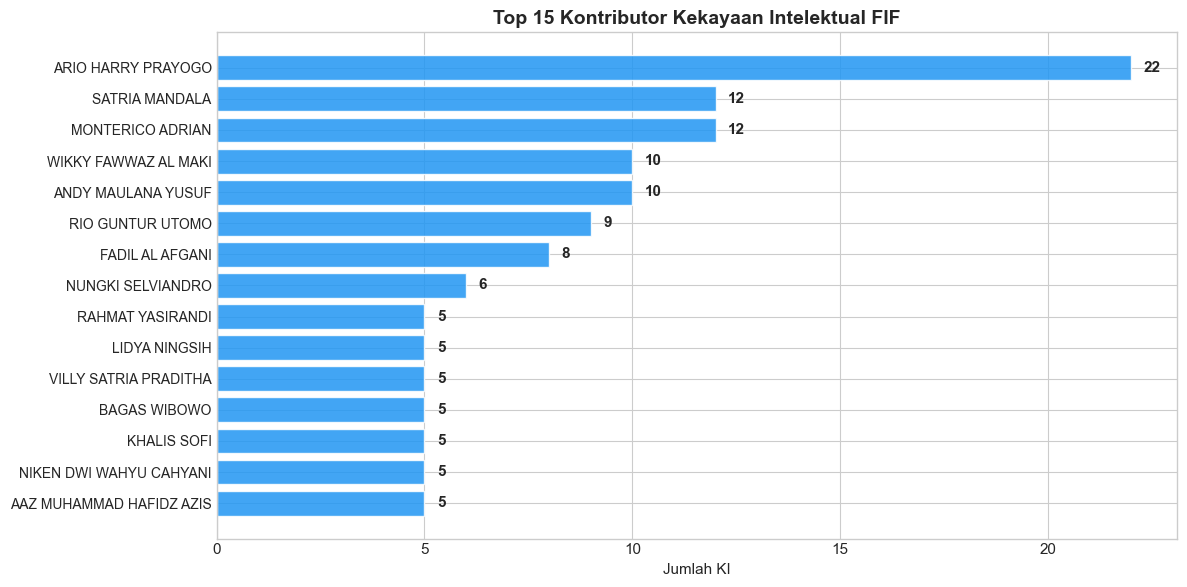

📌 Total kontributor unik: 92
📌 Kontributor dengan >1 KI: 57
📌 KI kolaboratif (>1 nama): 65 dari 147


In [8]:
all_names = []
for nama in df_ki['nama']:
    parts = [n.strip() for n in str(nama).split(',')]
    all_names.extend(parts)

name_counts = pd.Series(Counter(all_names)).sort_values(ascending=False)

fig, ax = plt.subplots(figsize=(12, 6))
top_n = 15
top = name_counts.head(top_n)
bars = ax.barh(range(len(top)), top.values, color=COLORS[0], alpha=0.85, edgecolor='white')
ax.set_yticks(range(len(top)))
ax.set_yticklabels(top.index, fontsize=10)
ax.invert_yaxis()

for bar, val in zip(bars, top.values):
    ax.text(bar.get_width() + 0.3, bar.get_y() + bar.get_height()/2,
            str(val), va='center', fontweight='bold', fontsize=11)

ax.set_xlabel('Jumlah KI')
ax.set_title(f'Top {top_n} Kontributor Kekayaan Intelektual FIF', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.savefig('../output/eda_05_ki_top_kontributor.png', bbox_inches='tight', dpi=150)
plt.show()

print(f'📌 Total kontributor unik: {name_counts.size}')
print(f'📌 Kontributor dengan >1 KI: {(name_counts > 1).sum()}')
print(f'📌 KI kolaboratif (>1 nama): {df_ki["nama"].str.contains(",").sum()} dari {len(df_ki)}')


### 3.5 KI Kolaboratif vs Individual


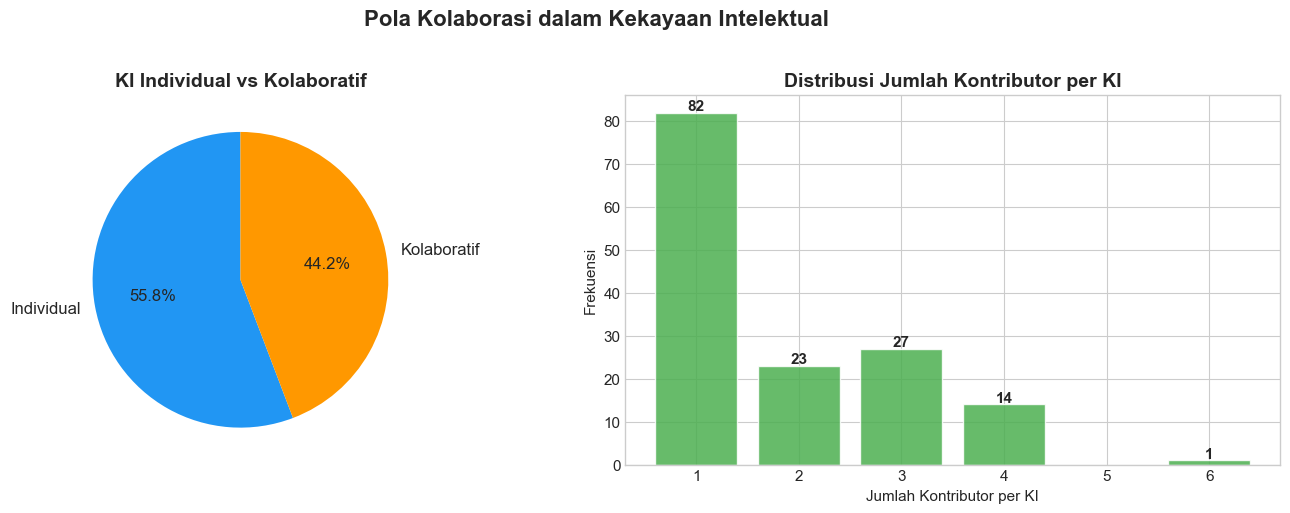

In [9]:
df_ki['is_kolaboratif'] = df_ki['nama'].str.contains(',')
df_ki['jumlah_kontributor'] = df_ki['nama'].apply(lambda x: len(str(x).split(',')))

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Proporsi kolaboratif
kolab_counts = df_ki['is_kolaboratif'].value_counts()
labels = ['Individual', 'Kolaboratif']
axes[0].pie(kolab_counts.values, labels=labels, autopct='%1.1f%%',
            colors=[COLORS[0], COLORS[2]], startangle=90, textprops={'fontsize': 12})
axes[0].set_title('KI Individual vs Kolaboratif')

# Distribusi jumlah kontributor
kontrib_dist = df_ki['jumlah_kontributor'].value_counts().sort_index()
axes[1].bar(kontrib_dist.index, kontrib_dist.values, color=COLORS[1], alpha=0.85, edgecolor='white')
axes[1].set_xlabel('Jumlah Kontributor per KI')
axes[1].set_ylabel('Frekuensi')
axes[1].set_title('Distribusi Jumlah Kontributor per KI')
axes[1].xaxis.set_major_locator(mticker.MaxNLocator(integer=True))

for x, y in zip(kontrib_dist.index, kontrib_dist.values):
    axes[1].text(x, y + 0.5, str(y), ha='center', fontweight='bold')

plt.suptitle('Pola Kolaborasi dalam Kekayaan Intelektual', fontsize=16, fontweight='bold', y=1.02)
plt.tight_layout()
plt.savefig('../output/eda_06_ki_kolaborasi.png', bbox_inches='tight', dpi=150)
plt.show()

df_ki.drop(columns=['is_kolaboratif', 'jumlah_kontributor'], inplace=True)


---

## 4️⃣ Analisis Data Startup FIF

### 4.1 Distribusi Startup per Tahun & Batch


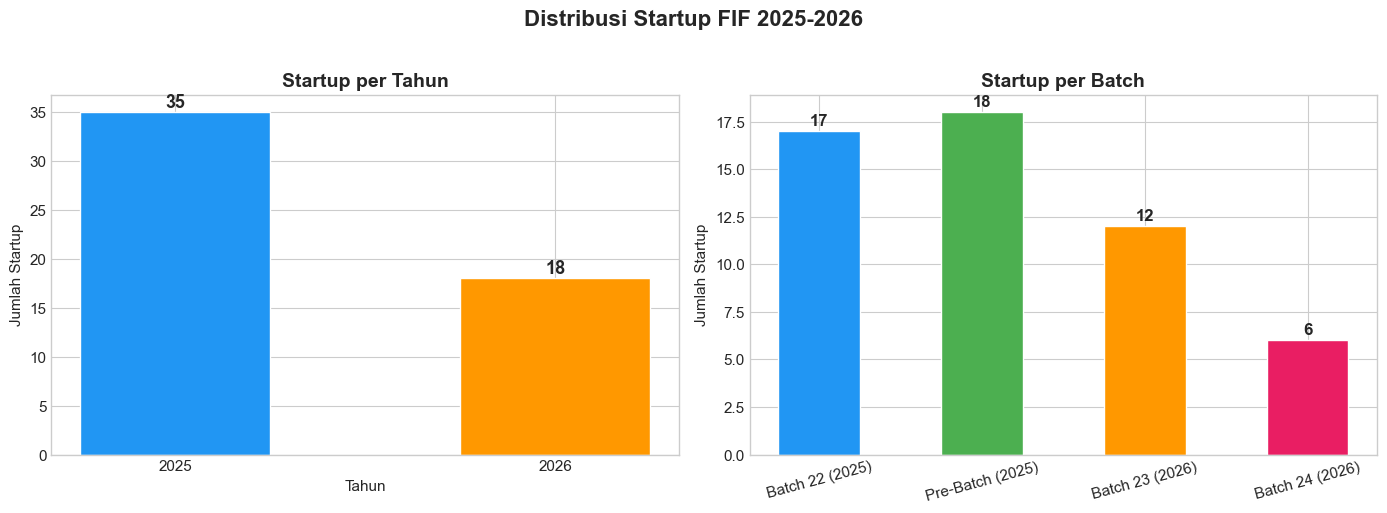

📌 Total startup: 53
📌 Tahun 2025: 35 startup
📌 Tahun 2026: 18 startup


In [10]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Per tahun
tahun_counts = df_st['tahun'].value_counts().sort_index()
bars = axes[0].bar(tahun_counts.index.astype(str), tahun_counts.values,
                    color=[COLORS[0], COLORS[2]], edgecolor='white', width=0.5)
for bar, val in zip(bars, tahun_counts.values):
    axes[0].text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.5,
                 str(val), ha='center', fontweight='bold', fontsize=13)
axes[0].set_xlabel('Tahun')
axes[0].set_ylabel('Jumlah Startup')
axes[0].set_title('Startup per Tahun')

# Per batch
batch_data = df_st.groupby(['tahun', 'batch'], dropna=False).size().reset_index(name='count')
labels_batch = []
for _, r in batch_data.iterrows():
    b = r['batch']
    t = int(r['tahun'])
    lbl = f'Batch {int(b)} ({t})' if pd.notna(b) else f'Pre-Batch ({t})'
    labels_batch.append(lbl)

bars = axes[1].bar(labels_batch, batch_data['count'],
                    color=[COLORS[i % len(COLORS)] for i in range(len(batch_data))],
                    edgecolor='white', width=0.5)
for bar, val in zip(bars, batch_data['count'].values):
    axes[1].text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.3,
                 str(val), ha='center', fontweight='bold', fontsize=12)
axes[1].set_ylabel('Jumlah Startup')
axes[1].set_title('Startup per Batch')
axes[1].tick_params(axis='x', rotation=15)

plt.suptitle('Distribusi Startup FIF 2025-2026', fontsize=16, fontweight='bold', y=1.02)
plt.tight_layout()
plt.savefig('../output/eda_07_startup_distribusi.png', bbox_inches='tight', dpi=150)
plt.show()

print(f'📌 Total startup: {len(df_st)}')
print(f'📌 Tahun 2025: {(df_st["tahun"]==2025).sum()} startup')
print(f'📌 Tahun 2026: {(df_st["tahun"]==2026).sum()} startup')


### 4.2 Analisis Deskripsi Startup


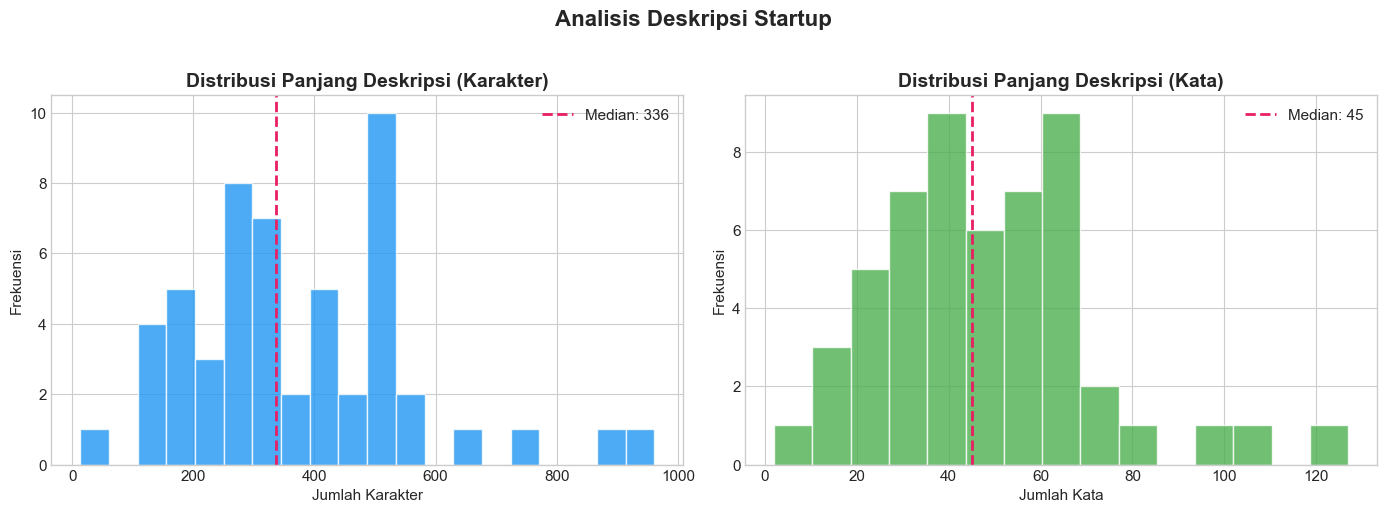

📌 Karakter: min=13, max=961, median=336
📌 Kata: min=2, max=127, median=45

⚠️ Startup dengan deskripsi terpendek:
   TED.Estate: 13 karakter, 2 kata
   Adosistering: 126 karakter, 18 kata
   DataByte Solution Indonesia: 145 karakter, 18 kata


In [11]:
df_st['desc_len'] = df_st['deskripsi'].str.len()
df_st['desc_words'] = df_st['deskripsi'].str.split().str.len()

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Histogram panjang deskripsi (karakter)
axes[0].hist(df_st['desc_len'], bins=20, color=COLORS[0], alpha=0.8, edgecolor='white')
axes[0].axvline(df_st['desc_len'].median(), color=COLORS[3], linestyle='--', linewidth=2, label=f'Median: {df_st["desc_len"].median():.0f}')
axes[0].set_xlabel('Jumlah Karakter')
axes[0].set_ylabel('Frekuensi')
axes[0].set_title('Distribusi Panjang Deskripsi (Karakter)')
axes[0].legend()

# Histogram panjang deskripsi (kata)
axes[1].hist(df_st['desc_words'], bins=15, color=COLORS[1], alpha=0.8, edgecolor='white')
axes[1].axvline(df_st['desc_words'].median(), color=COLORS[3], linestyle='--', linewidth=2, label=f'Median: {df_st["desc_words"].median():.0f}')
axes[1].set_xlabel('Jumlah Kata')
axes[1].set_ylabel('Frekuensi')
axes[1].set_title('Distribusi Panjang Deskripsi (Kata)')
axes[1].legend()

plt.suptitle('Analisis Deskripsi Startup', fontsize=16, fontweight='bold', y=1.02)
plt.tight_layout()
plt.savefig('../output/eda_08_startup_deskripsi.png', bbox_inches='tight', dpi=150)
plt.show()

print(f'📌 Karakter: min={df_st["desc_len"].min()}, max={df_st["desc_len"].max()}, median={df_st["desc_len"].median():.0f}')
print(f'📌 Kata: min={df_st["desc_words"].min()}, max={df_st["desc_words"].max()}, median={df_st["desc_words"].median():.0f}')

shortest = df_st.nsmallest(3, 'desc_len')[['nama_startup', 'desc_len', 'desc_words']]
print('\n⚠️ Startup dengan deskripsi terpendek:')
for _, r in shortest.iterrows():
    print(f'   {r["nama_startup"]}: {r["desc_len"]} karakter, {r["desc_words"]} kata')

df_st.drop(columns=['desc_len', 'desc_words'], inplace=True)


### 4.3 Top Kata Kunci Deskripsi Startup


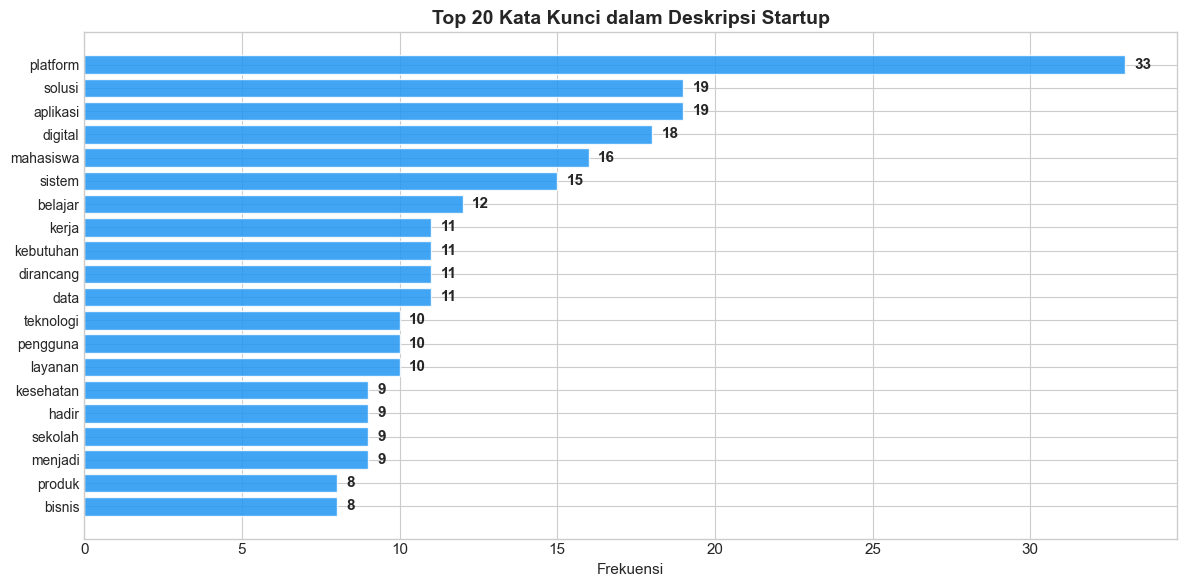

In [12]:
STOPWORDS_ID = {
    'yang', 'dan', 'di', 'ini', 'dengan', 'untuk', 'dari', 'pada', 'adalah',
    'ke', 'tidak', 'akan', 'juga', 'sudah', 'atau', 'agar', 'serta', 'oleh',
    'dalam', 'secara', 'lebih', 'bagi', 'kami', 'mereka', 'dapat', 'bisa',
    'telah', 'ada', 'seperti', 'saat', 'melalui', 'sebuah', 'antara', 'hanya',
    'karena', 'itu', 'sebagai', 'sehingga', 'tanpa', 'baik', 'sangat', 'tersebut',
    'berupa', 'maupun', 'hingga', 'namun', 'masih', 'yaitu', 'lainnya',
    'membantu', 'berbasis', 'menggunakan', 'meliputi', 'memiliki', 'menyediakan',
    'the', 'a', 'an', 'and', 'or', 'of', 'to', 'in', 'for', 'is', 'are', 'was',
}

all_words = []
for desc in df_st['deskripsi']:
    words = re.findall(r'[a-zA-Z]{3,}', str(desc).lower())
    all_words.extend([w for w in words if w not in STOPWORDS_ID])

word_freq = Counter(all_words).most_common(20)

fig, ax = plt.subplots(figsize=(12, 6))
words, counts = zip(*word_freq)
bars = ax.barh(range(len(words)), counts, color=COLORS[0], alpha=0.85, edgecolor='white')
ax.set_yticks(range(len(words)))
ax.set_yticklabels(words, fontsize=10)
ax.invert_yaxis()

for bar, val in zip(bars, counts):
    ax.text(bar.get_width() + 0.3, bar.get_y() + bar.get_height()/2,
            str(val), va='center', fontweight='bold')

ax.set_xlabel('Frekuensi')
ax.set_title('Top 20 Kata Kunci dalam Deskripsi Startup', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.savefig('../output/eda_09_startup_keywords.png', bbox_inches='tight', dpi=150)
plt.show()


---

## 5️⃣ Analisis Peserta Inkubasi FIF 2025

### 5.1 Ukuran Tim per Startup


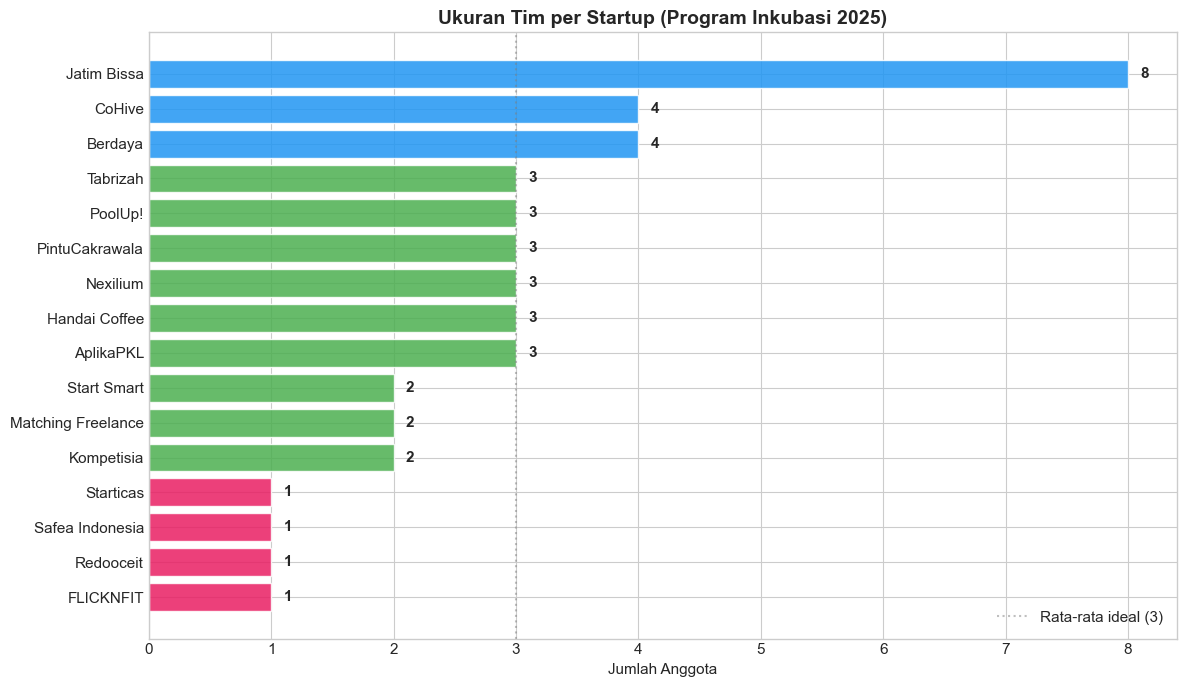

📌 Total peserta inkubasi: 44
📌 Total startup: 16
📌 Rata-rata anggota per startup: 2.8
📌 Tim terbesar: Jatim Bissa (8 anggota)
📌 Tim 1 anggota: 4 startup


In [13]:
tim_size = df_ink.groupby('nama_startup').size().sort_values(ascending=True).reset_index(name='jumlah_anggota')

fig, ax = plt.subplots(figsize=(12, 7))
colors_bar = [COLORS[3] if s <= 1 else COLORS[1] if s <= 3 else COLORS[0] for s in tim_size['jumlah_anggota']]
bars = ax.barh(tim_size['nama_startup'], tim_size['jumlah_anggota'], color=colors_bar,
               alpha=0.85, edgecolor='white')

for bar, val in zip(bars, tim_size['jumlah_anggota']):
    ax.text(bar.get_width() + 0.1, bar.get_y() + bar.get_height()/2,
            str(val), va='center', fontweight='bold', fontsize=11)

ax.set_xlabel('Jumlah Anggota')
ax.set_title('Ukuran Tim per Startup (Program Inkubasi 2025)', fontsize=14, fontweight='bold')
ax.axvline(x=3, color='gray', linestyle=':', alpha=0.5, label='Rata-rata ideal (3)')
ax.legend()
plt.tight_layout()
plt.savefig('../output/eda_10_inkubasi_ukuran_tim.png', bbox_inches='tight', dpi=150)
plt.show()

print(f'📌 Total peserta inkubasi: {len(df_ink)}')
print(f'📌 Total startup: {df_ink["nama_startup"].nunique()}')
print(f'📌 Rata-rata anggota per startup: {len(df_ink)/df_ink["nama_startup"].nunique():.1f}')
print(f'📌 Tim terbesar: {tim_size.iloc[-1]["nama_startup"]} ({tim_size.iloc[-1]["jumlah_anggota"]} anggota)')
print(f'📌 Tim 1 anggota: {(tim_size["jumlah_anggota"]==1).sum()} startup')


### 5.2 Distribusi Prodi & Universitas


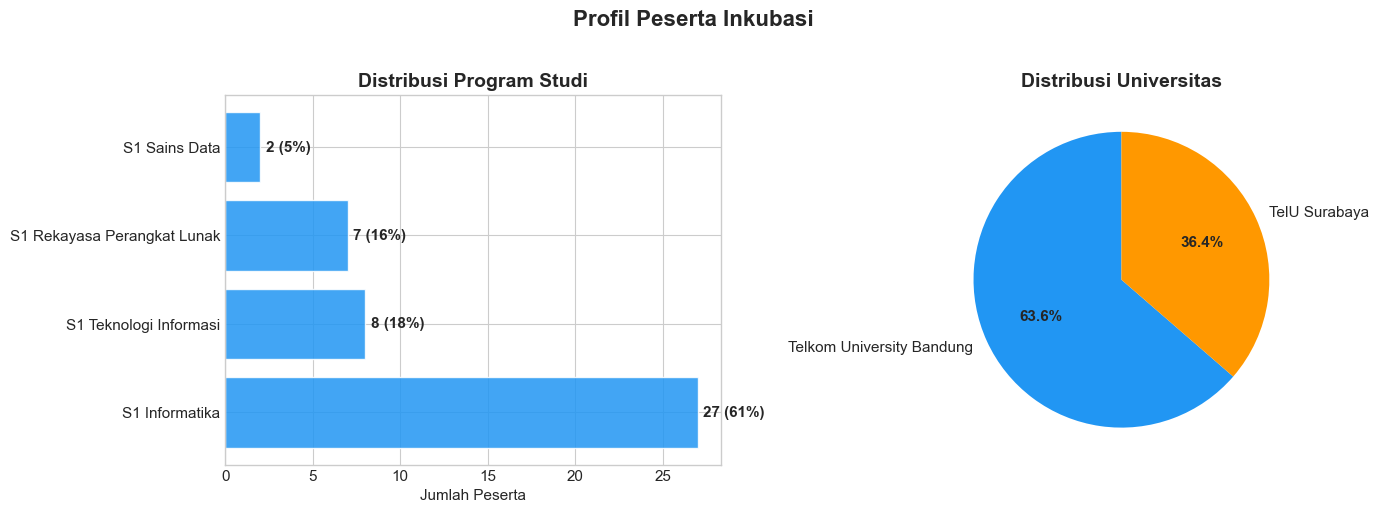

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Prodi
prodi_counts = df_ink['prodi'].value_counts()
bars = axes[0].barh(prodi_counts.index, prodi_counts.values, color=COLORS[0], alpha=0.85, edgecolor='white')
for bar, val in zip(bars, prodi_counts.values):
    axes[0].text(bar.get_width() + 0.3, bar.get_y() + bar.get_height()/2,
                 f'{val} ({val/len(df_ink)*100:.0f}%)', va='center', fontweight='bold')
axes[0].set_xlabel('Jumlah Peserta')
axes[0].set_title('Distribusi Program Studi')

# Universitas
univ_counts = df_ink['universitas'].value_counts()
wedges, texts, autotexts = axes[1].pie(
    univ_counts.values, labels=univ_counts.index, autopct='%1.1f%%',
    colors=[COLORS[0], COLORS[2]], startangle=90, textprops={'fontsize': 11}
)
for t in autotexts:
    t.set_fontweight('bold')
axes[1].set_title('Distribusi Universitas')

plt.suptitle('Profil Peserta Inkubasi', fontsize=16, fontweight='bold', y=1.02)
plt.tight_layout()
plt.savefig('../output/eda_11_inkubasi_prodi_univ.png', bbox_inches='tight', dpi=150)
plt.show()


### 5.3 Heatmap: Prodi × Universitas


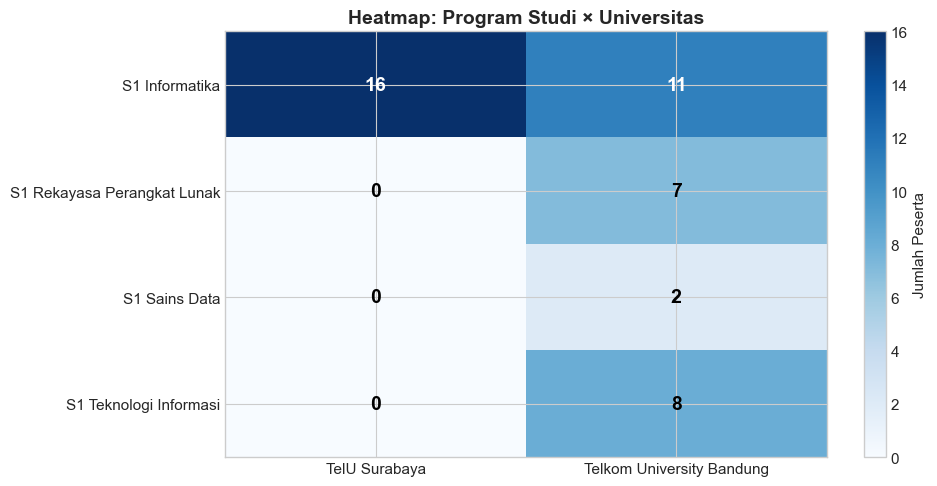

📌 TelU Surabaya: 100% dari S1 Informatika
📌 TelU Bandung: gabungan dari 4 prodi (Informatika, RPL, TI, Sains Data)


In [15]:
ct = pd.crosstab(df_ink['prodi'], df_ink['universitas'])

fig, ax = plt.subplots(figsize=(10, 5))
im = ax.imshow(ct.values, cmap='Blues', aspect='auto')

ax.set_xticks(range(len(ct.columns)))
ax.set_xticklabels(ct.columns, fontsize=11)
ax.set_yticks(range(len(ct.index)))
ax.set_yticklabels(ct.index, fontsize=11)

for i in range(len(ct.index)):
    for j in range(len(ct.columns)):
        val = ct.values[i, j]
        color = 'white' if val > ct.values.max() / 2 else 'black'
        ax.text(j, i, str(val), ha='center', va='center', fontweight='bold',
                fontsize=14, color=color)

plt.colorbar(im, label='Jumlah Peserta')
ax.set_title('Heatmap: Program Studi × Universitas', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.savefig('../output/eda_12_inkubasi_heatmap.png', bbox_inches='tight', dpi=150)
plt.show()

print('📌 TelU Surabaya: 100% dari S1 Informatika')
print('📌 TelU Bandung: gabungan dari 4 prodi (Informatika, RPL, TI, Sains Data)')


---

## 6️⃣ Analisis Lintas Dataset

### 6.1 Kesesuaian Startup: Data Startup vs Peserta Inkubasi


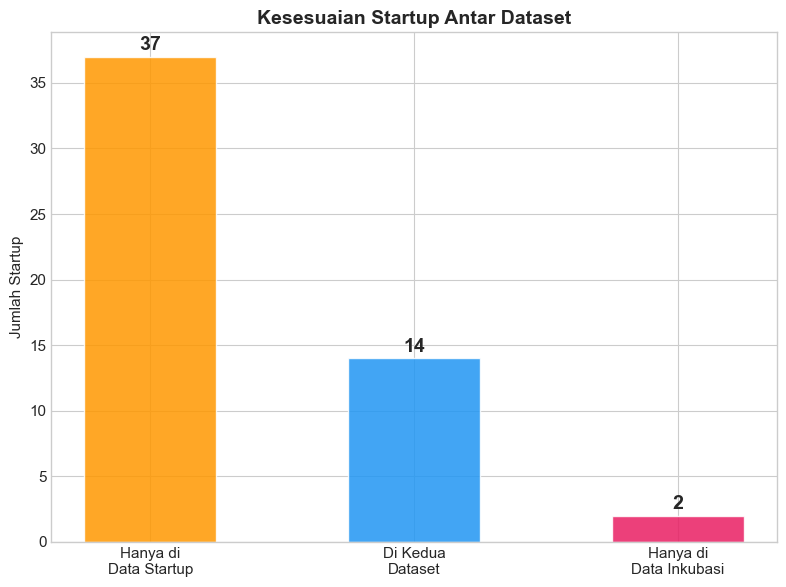

📌 Startup di Data Startup: 51
📌 Startup di Data Inkubasi: 16
📌 Overlap: 14 startup

⚠️ Hanya di Data Inkubasi (tidak ada di master): {'aplikapkl', 'start smart'}
ℹ️ Hanya di Data Startup (belum ikut inkubasi): 37 startup


In [16]:
ink_startups = set(df_ink['nama_startup'].str.lower().unique())
st_startups = set(df_st['nama_startup'].str.lower().unique())

overlap = ink_startups & st_startups
only_ink = ink_startups - st_startups
only_st = st_startups - ink_startups

fig, ax = plt.subplots(figsize=(8, 6))
categories = ['Hanya di\nData Startup', 'Di Kedua\nDataset', 'Hanya di\nData Inkubasi']
values = [len(only_st), len(overlap), len(only_ink)]
colors_v = [COLORS[2], COLORS[0], COLORS[3]]

bars = ax.bar(categories, values, color=colors_v, alpha=0.85, edgecolor='white', width=0.5)
for bar, val in zip(bars, values):
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.5,
            str(val), ha='center', fontweight='bold', fontsize=14)

ax.set_ylabel('Jumlah Startup')
ax.set_title('Kesesuaian Startup Antar Dataset', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.savefig('../output/eda_13_cross_dataset.png', bbox_inches='tight', dpi=150)
plt.show()

print(f'📌 Startup di Data Startup: {len(st_startups)}')
print(f'📌 Startup di Data Inkubasi: {len(ink_startups)}')
print(f'📌 Overlap: {len(overlap)} startup')
print(f'\n⚠️ Hanya di Data Inkubasi (tidak ada di master): {only_ink}')
print(f'ℹ️ Hanya di Data Startup (belum ikut inkubasi): {len(only_st)} startup')


### 6.2 Data Quality Flags Summary


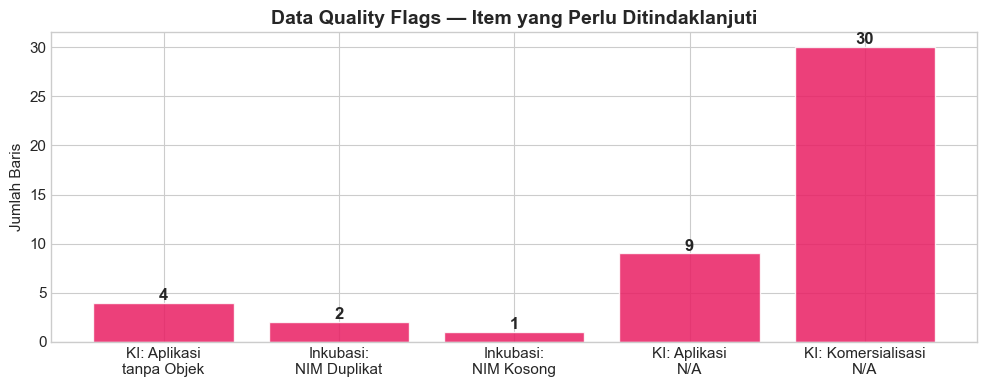

In [17]:
fig, ax = plt.subplots(figsize=(10, 4))

flags = {
    'KI: Aplikasi\ntanpa Objek': df_ki['flag_aplikasi_tanpa_objek'].sum(),
    'Inkubasi:\nNIM Duplikat': df_ink['flag_nim_duplikat'].sum(),
    'Inkubasi:\nNIM Kosong': df_ink['nim'].isna().sum(),
    'KI: Aplikasi\nN/A': df_ki['sudah_di_aplikasikan'].isna().sum(),
    'KI: Komersialisasi\nN/A': df_ki['sudah_di_komersialisasikan'].isna().sum(),
}

colors_f = [COLORS[3] if v > 0 else COLORS[1] for v in flags.values()]
bars = ax.bar(flags.keys(), flags.values(), color=colors_f, alpha=0.85, edgecolor='white')
for bar, val in zip(bars, flags.values()):
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.3,
            str(val), ha='center', fontweight='bold', fontsize=12)

ax.set_ylabel('Jumlah Baris')
ax.set_title('Data Quality Flags — Item yang Perlu Ditindaklanjuti', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.savefig('../output/eda_14_quality_flags.png', bbox_inches='tight', dpi=150)
plt.show()


---

## 7️⃣ Temuan Utama (Key Findings)

### Kekayaan Intelektual (KI)
1. **HAK CIPTA mendominasi** dengan 132 dari 147 KI (89.8%), diikuti Desain Industri (7), Paten (6), dan Merek (2)
2. **Tingkat sertifikasi tinggi**: 141 dari 147 (95.9%) sudah berstatus "Sertifikat Selesai"
3. **Tingkat aplikasi ~35.5%** dari yang terdata — masih ada ruang peningkatan
4. **Tingkat komersialisasi ~32.5%** — lebih rendah dari tingkat aplikasi
5. **PATEN belum ada yang diaplikasikan** (0 dari 6) — semua 6 paten juga belum ada data komersialisasi
6. **Top kontributor**: Ario Harry Prayogo (14 KI), Wikky Fawwaz Al Maki (10 KI), Satria Mandala (8 KI)
7. **44.2% KI bersifat kolaboratif** (melibatkan >1 kontributor)

### Startup FIF
8. **53 startup** terdaftar — 35 di tahun 2025, 18 di tahun 2026
9. Tahun 2025 terbagi antara **Pre-Batch** (18 startup) dan **Batch 22** (17 startup)
10. Rata-rata panjang deskripsi startup: ~377 karakter (~57 kata)

### Program Inkubasi
11. **44 peserta** dari **16 startup** mengikuti program inkubasi 2025
12. **S1 Informatika mendominasi** dengan 27 dari 44 peserta (61.4%)
13. **TelU Surabaya hanya kontribusi peserta S1 Informatika** — tidak ada diversitas prodi
14. **Tim terbesar**: Jatim Bissa (8 anggota), **4 startup** hanya punya 1 anggota
15. **1 NIM duplikat**: Mahasiswa 5760 terdaftar di FLICKNFIT dan Starticas sekaligus

### Cross-Dataset
16. **2 startup inkubasi tidak terdaftar** di data master startup (Start Smart, AplikaPKL)
17. Hanya **14 dari 51** startup unik yang memiliki data peserta inkubasi


---

## 8️⃣ Rekomendasi

1. **Verifikasi NIM duplikat** — Konfirmasi apakah Mahasiswa 5760 memang aktif di 2 startup
2. **Lengkapi NIM kosong** — Mahasiswa 1677 (Redooceit) tidak memiliki NIM
3. **Update data master startup** — Tambahkan Start Smart dan AplikaPKL ke data startup
4. **Dorong aplikasi & komersialisasi PATEN** — Semua 6 paten belum diaplikasikan
5. **Tingkatkan diversitas prodi di TelU Surabaya** — Saat ini 100% S1 Informatika
6. **Review startup 1 anggota** — 4 startup inkubasi hanya punya 1 orang, perlu penambahan anggota?
7. **Isi data aplikasi & komersialisasi yang kosong** — 9 KI tanpa status aplikasi, 30 tanpa status komersialisasi
